In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("Admission_Prediction_TimeSeries_Ready.csv")

print("Rows and columns:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFirst five records:")
display(df.head())

Rows and columns: (1000, 12)

Available columns:
['Serial No.', 'GRE Score', 'TOEFL Score', 'University Rating', 'SOP', 'LOR', 'CGPA', 'Research', 'Chance of Admit', 'Application_DateTime', 'University_Name', 'region']

First five records:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
0,1,337,118,4,4.5,4.5,9.65,1,0.92,2022-01-01 09:00:00,Indian Institute of Technology Kharagpur,East
1,2,324,107,4,4.0,4.5,8.87,1,0.76,2022-01-02 09:00:00,National Institute of Technology Karnataka,South
2,3,316,104,3,3.0,3.5,8.00,1,0.72,2022-01-04 09:00:00,Gujarat University,West
3,4,322,110,3,3.5,2.5,8.67,1,0.80,2022-01-06 09:00:00,Jamia Millia Islamia,North
4,5,314,103,2,2.0,3.0,8.21,0,0.65,2022-01-08 09:00:00,Jamia Millia Islamia,North


In [3]:
# Check types, missing values, duplicates, and numerical summaries.
print("Column data types:")
display(df.dtypes.to_frame("Data Type"))

print("\nMissing values per column:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nNumerical summary:")
display(df.describe().T)

Column data types:


,Data Type
Serial No.,int64
GRE Score,int64
TOEFL Score,int64
University Rating,int64
SOP,float64
LOR,float64
CGPA,float64
Research,int64
Chance of Admit,float64
Application_DateTime,object



Missing values per column:


,Missing Values
Serial No.,0
GRE Score,0
TOEFL Score,0
University Rating,0
SOP,0
LOR,0
CGPA,0
Research,0
Chance of Admit,0
Application_DateTime,0



Duplicate rows: 0

Numerical summary:


,count,mean,std,min,25%,50%,75%,max
Serial No.,1000.0,500.50000,288.819436,1.00,250.7500,500.50,750.25,1000.00
GRE Score,1000.0,315.96500,13.415653,290.00,305.0000,316.00,326.25,340.00
TOEFL Score,1000.0,106.56400,7.634277,92.00,101.0000,107.00,113.00,120.00
University Rating,1000.0,3.01500,1.317768,1.00,2.0000,3.00,4.00,5.00
SOP,1000.0,3.39350,1.027279,0.90,2.5000,3.50,4.00,5.10
LOR,1000.0,3.40670,0.891864,0.90,3.0000,3.50,4.00,5.10
CGPA,1000.0,8.58979,0.612170,6.77,8.1800,8.58,9.07,9.95
Research,1000.0,0.50300,0.500241,0.00,0.0000,1.00,1.00,1.00
Chance of Admit,1000.0,0.71777,0.145910,0.32,0.6375,0.72,0.82,0.97


In [4]:
# These are common admission applicant features.
# The list is filtered so the notebook still runs if a column is absent.
candidate_features = [
    "GRE Score",
    "TOEFL Score",
    "CGPA",
    "SOP",
    "LOR",
    "Chance of Admit"
]
features = [col for col in candidate_features if col in df.columns]

if not features:
    print("No expected numerical columns were found. Check the column names above.")
else:
    print("Features selected for distribution analysis:")
    print(features)

    # Convert chosen columns to numeric where possible.
    # Unparseable values become NaN and are ignored by the plots.
    for col in features:
        df[col] = pd.to_numeric(df[col], errors="coerce")

Features selected for distribution analysis:
['GRE Score', 'TOEFL Score', 'CGPA', 'SOP', 'LOR', 'Chance of Admit']


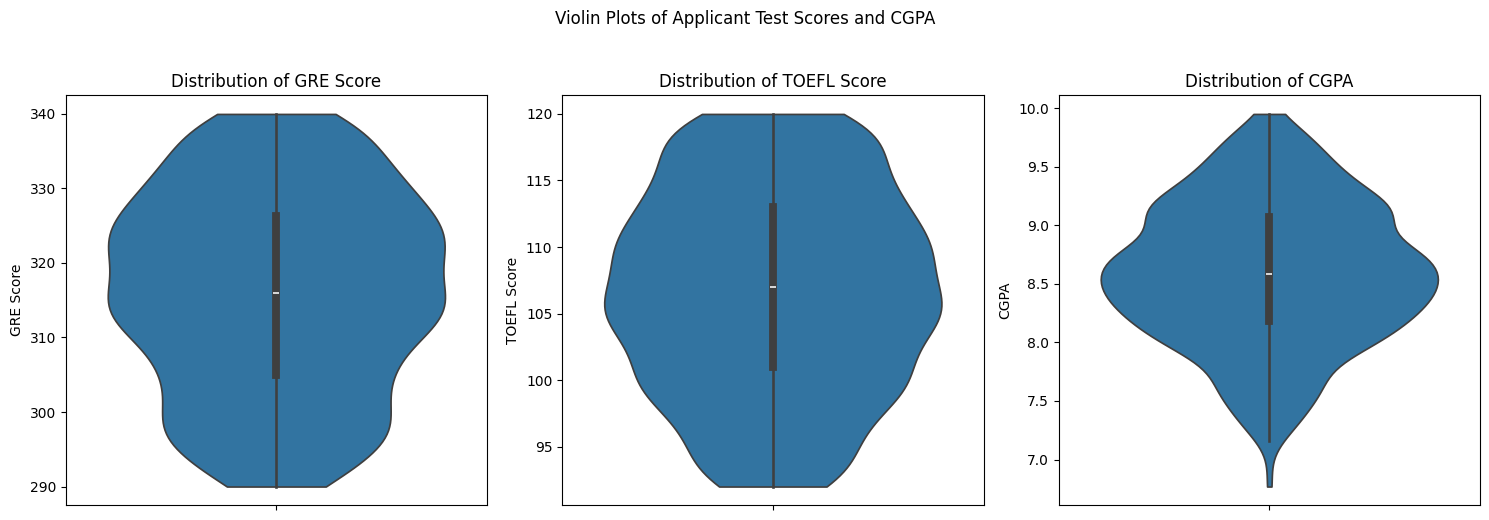

In [5]:
# A violin plot shows the distribution shape.
# Wider areas mean more observations occur around those values.
# The inner box shows the median and interquartile range.
violin_features = [
    col for col in ["GRE Score", "TOEFL Score", "CGPA"] if col in df.columns
]

if violin_features:
    fig, axes = plt.subplots(
        nrows=1,
        ncols=len(violin_features),
        figsize=(5 * len(violin_features), 5)
    )

    # When there is one plot, convert the single axis into a list.
    if len(violin_features) == 1:
        axes = [axes]

    for ax, feature in zip(axes, violin_features):
        sns.violinplot(
            data=df,
            y=feature,
            inner="box",
            cut=0,
            ax=ax
        )
        ax.set_title(f"Distribution of {feature}")
        ax.set_xlabel("")
        ax.set_ylabel(feature)

    plt.suptitle("Violin Plots of Applicant Test Scores and CGPA", y=1.03)
    plt.tight_layout()
    plt.show()
else:
    print("GRE Score, TOEFL Score, and CGPA were not found.")

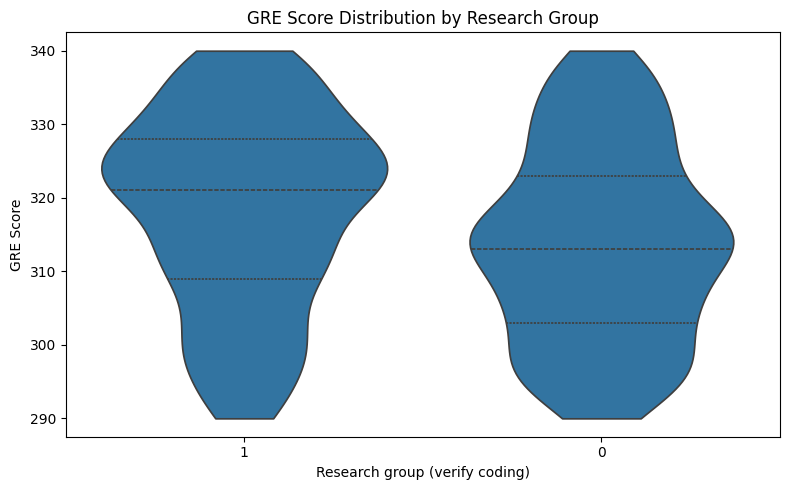

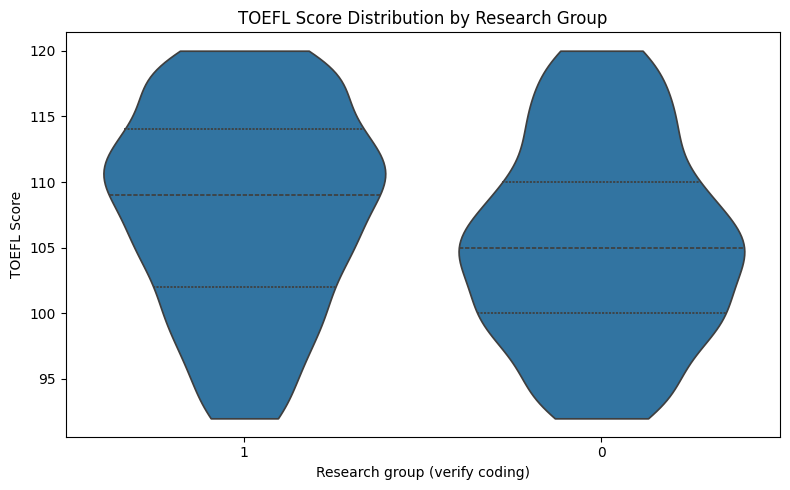

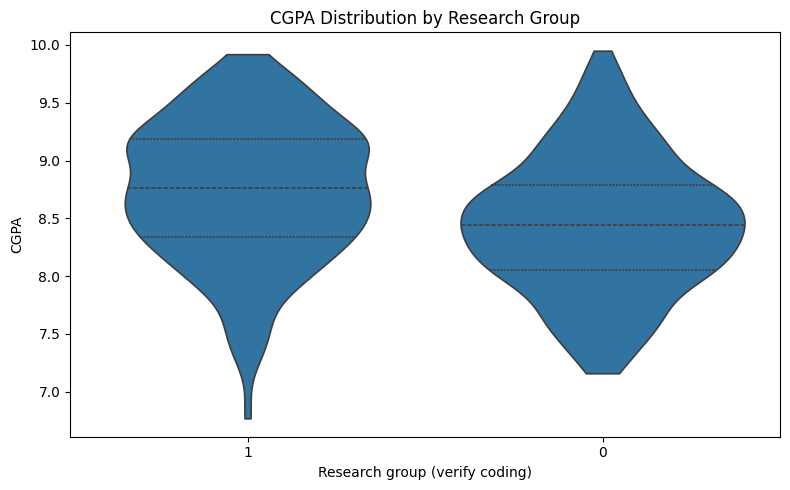

In [6]:
# This comparison helps show whether the distribution of scores differs
# between applicants with different Research values.
# Check the dataset documentation to understand how Research is coded.
group_features = [
    col for col in ["GRE Score", "TOEFL Score", "CGPA"] if col in df.columns
]

if "Research" in df.columns and group_features:
    plot_df = df.dropna(subset=["Research"]).copy()
    plot_df["Research Group"] = plot_df["Research"].astype(str)

    for feature in group_features:
        plt.figure(figsize=(8, 5))
        sns.violinplot(
            data=plot_df,
            x="Research Group",
            y=feature,
            inner="quartile",
            cut=0
        )
        plt.title(f"{feature} Distribution by Research Group")
        plt.xlabel("Research group (verify coding)")
        plt.ylabel(feature)
        plt.tight_layout()
        plt.show()
else:
    print("Research or the selected numerical features are not available.")

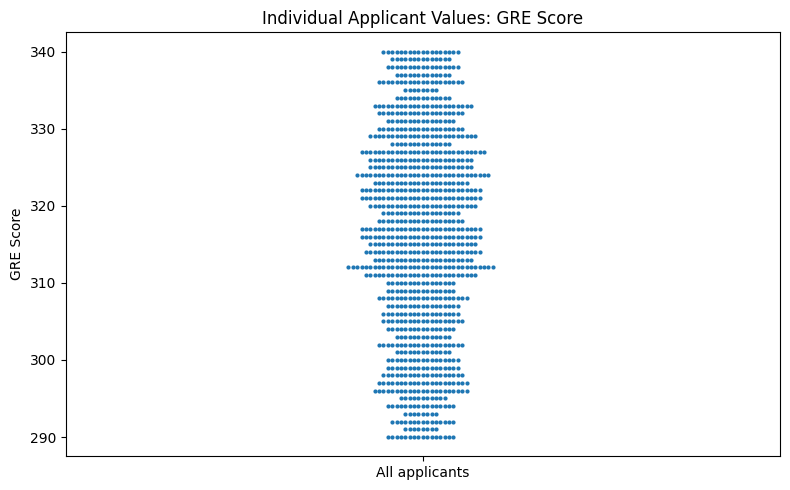

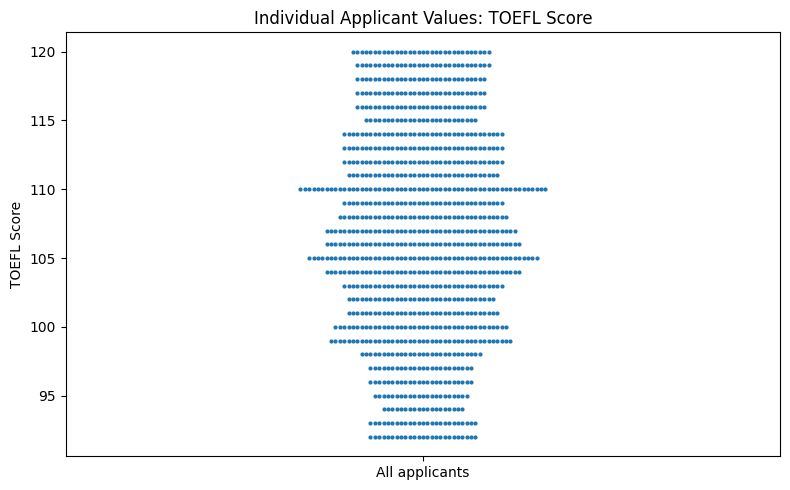

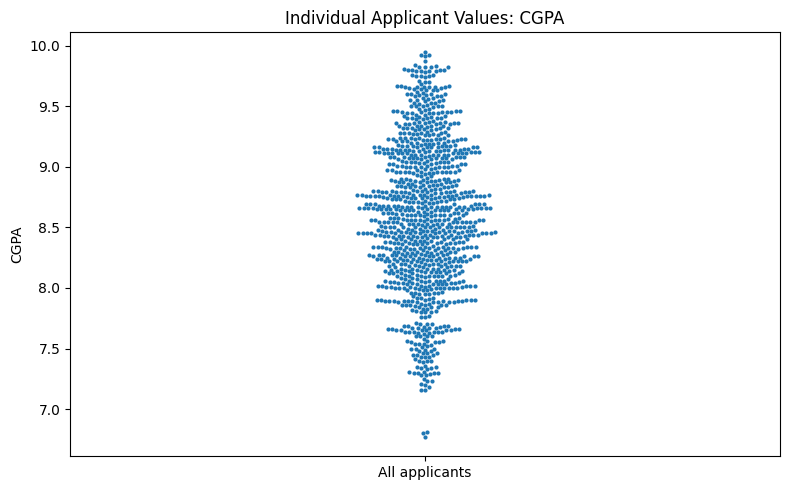

In [8]:
# Each point represents one applicant.
# Swarm plots spread nearby points so overlapping observations are easier to see.
# Plot each feature separately because test scores and CGPA use different scales.
swarm_features = [
    col for col in ["GRE Score", "TOEFL Score", "CGPA"] if col in df.columns
]

if swarm_features:
    for feature in swarm_features:
        plot_df = df.dropna(subset=[feature]).copy()

        # A single group places all applicants on one axis.
        plot_df["Applicant Group"] = "All applicants"

        plt.figure(figsize=(8, 5))
        sns.swarmplot(
            data=plot_df,
            x="Applicant Group",
            y=feature,
            size=3
        )
        plt.title(f"Individual Applicant Values: {feature}")
        plt.xlabel("")
        plt.ylabel(feature)
        plt.tight_layout()
        plt.show()
else:
    print("No test-score or CGPA columns were found.")

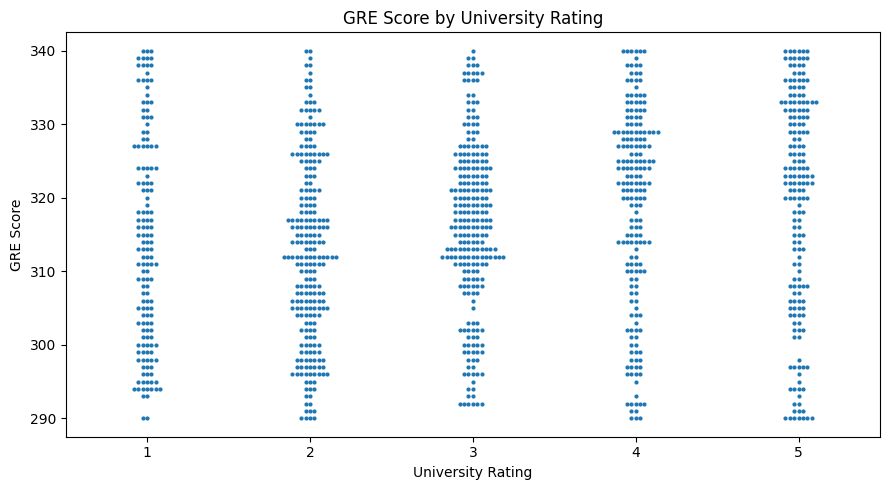

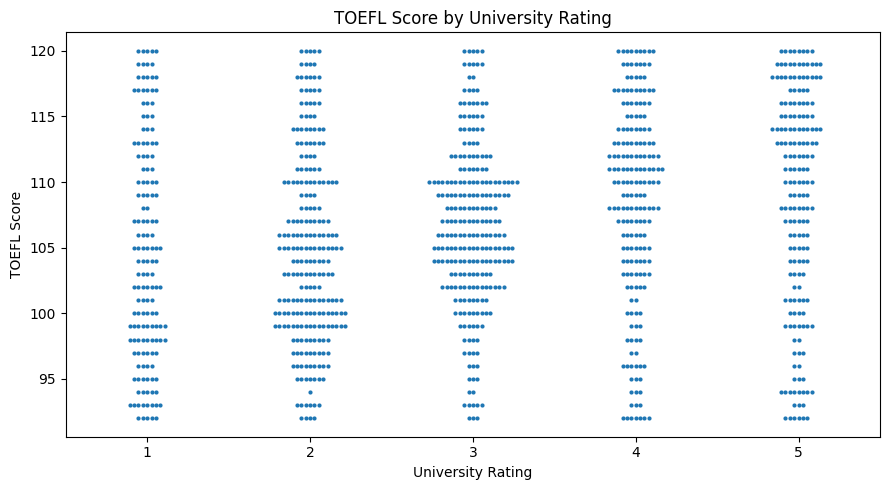

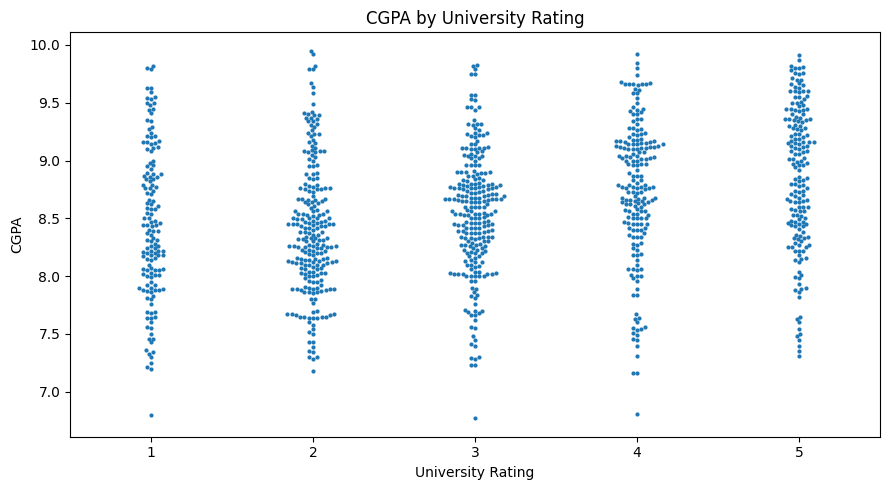

In [9]:
# If University Rating is available, compare individual applicant values
# across rating groups to reveal spread, clusters, and unusual observations.
comparison_features = [
    col for col in ["GRE Score", "TOEFL Score", "CGPA"] if col in df.columns
]

if "University Rating" in df.columns and comparison_features:
    plot_df = df.dropna(subset=["University Rating"]).copy()

    for feature in comparison_features:
        feature_df = plot_df.dropna(subset=[feature])

        plt.figure(figsize=(9, 5))
        sns.swarmplot(
            data=feature_df,
            x="University Rating",
            y=feature,
            size=3
        )
        plt.title(f"{feature} by University Rating")
        plt.xlabel("University Rating")
        plt.ylabel(feature)
        plt.tight_layout()
        plt.show()
else:
    print("University Rating or applicant score columns are missing.")

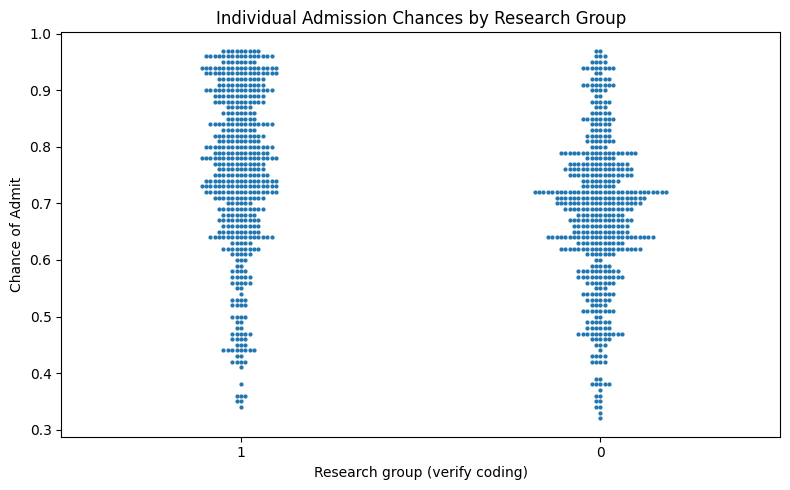

In [10]:
# This optional view examines individual admission-chance values by research group.
if "Research" in df.columns and "Chance of Admit" in df.columns:
    plot_df = df.dropna(subset=["Research", "Chance of Admit"]).copy()
    plot_df["Research Group"] = plot_df["Research"].astype(str)

    plt.figure(figsize=(8, 5))
    sns.swarmplot(
        data=plot_df,
        x="Research Group",
        y="Chance of Admit",
        size=3
    )
    plt.title("Individual Admission Chances by Research Group")
    plt.xlabel("Research group (verify coding)")
    plt.ylabel("Chance of Admit")
    plt.tight_layout()
    plt.show()
else:
    print("Research or Chance of Admit column is missing.")

In [11]:
# Summarize each selected feature with mean, median, standard deviation,
# quartiles, and potential outlier counts using the IQR rule.
# IQR flags are prompts for review, not proof that data is incorrect.
summary_rows = []

for feature in features:
    values = pd.to_numeric(df[feature], errors="coerce").dropna()

    if values.empty:
        continue

    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    potential_outliers = values[
        (values < lower_bound) | (values > upper_bound)
    ]

    summary_rows.append({
        "Feature": feature,
        "Count": values.count(),
        "Mean": values.mean(),
        "Median": values.median(),
        "Standard Deviation": values.std(),
        "Minimum": values.min(),
        "Q1": q1,
        "Q3": q3,
        "Maximum": values.max(),
        "Potential Outlier Count": len(potential_outliers)
    })

distribution_summary = pd.DataFrame(summary_rows)

if not distribution_summary.empty:
    display(distribution_summary.round(3))
else:
    print("No selected features contain usable numerical values.")

,Feature,Count,Mean,Median,Standard Deviation,Minimum,Q1,Q3,Maximum,Potential Outlier Count
0,GRE Score,1000,315.965,316.00,13.416,290.00,305.000,326.25,340.00,0
1,TOEFL Score,1000,106.564,107.00,7.634,92.00,101.000,113.00,120.00,0
2,CGPA,1000,8.590,8.58,0.612,6.77,8.180,9.07,9.95,3
3,SOP,1000,3.394,3.50,1.027,0.90,2.500,4.00,5.10,0
4,LOR,1000,3.407,3.50,0.892,0.90,3.000,4.00,5.10,6
5,Chance of Admit,1000,0.718,0.72,0.146,0.32,0.638,0.82,0.97,14


In [12]:
# Show the rows whose values fall outside the IQR bounds for each feature.
# Review these records against the source data before correcting or removing anything.
for feature in features:
    values = pd.to_numeric(df[feature], errors="coerce")
    valid_values = values.dropna()

    if valid_values.empty:
        continue

    q1 = valid_values.quantile(0.25)
    q3 = valid_values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    mask = values.notna() & ((values < lower_bound) | (values > upper_bound))

    if mask.any():
        print(f"Potential outliers for {feature}:")
        display(df.loc[mask].head(20))
    else:
        print(f"No IQR-flagged values found for {feature}.")

No IQR-flagged values found for GRE Score.
No IQR-flagged values found for TOEFL Score.
Potential outliers for CGPA:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
58,59,300,99,1,3.0,2.0,6.80,1,0.36,2022-04-17 09:00:00,National Institute of Technology Tiruchirappalli,South
724,725,302,109,4,1.5,3.5,6.81,1,0.83,2025-08-15 09:00:00,National Institute of Technology Warangal,South
779,780,318,109,3,4.0,2.0,6.77,1,0.36,2025-11-24 09:00:00,Visvesvaraya Technological University,South


No IQR-flagged values found for SOP.
Potential outliers for LOR:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
347,348,299,94,1,1.0,1.0,7.34,0,0.42,2023-09-26 09:00:00,University of Madras,South
506,507,290,99,2,3.9,1.4,9.79,1,0.45,2024-07-13 09:00:00,SRM Institute of Science and Technology,South
664,665,333,116,3,4.6,1.0,8.44,0,0.74,2025-04-28 09:00:00,Thapar Institute of Engineering and Technology,North
725,726,338,93,2,2.6,1.0,7.43,1,0.90,2025-08-17 09:00:00,Indian Institute of Technology Hyderabad,South
735,736,337,92,4,3.0,1.0,8.56,1,0.58,2025-09-04 09:00:00,Gujarat University,West
859,860,305,99,5,2.4,0.9,8.22,1,0.83,2026-04-18 09:00:00,National Institute of Technology Rourkela,East


Potential outliers for Chance of Admit:


,Serial No.,GRE Score,TOEFL Score,University Rating,SOP,LOR,CGPA,Research,Chance of Admit,Application_DateTime,University_Name,region
58,59,300,99,1,3.0,2.0,6.80,1,0.36,2022-04-17 09:00:00,National Institute of Technology Tiruchirappalli,South
92,93,298,98,2,4.0,3.0,8.03,0,0.34,2022-06-18 09:00:00,Visvesvaraya Technological University,South
94,95,303,99,3,2.0,2.5,7.66,0,0.36,2022-06-21 09:00:00,Osmania University,South
376,377,297,96,2,2.5,2.0,7.43,0,0.34,2023-11-18 09:00:00,National Institute of Technology Tiruchirappalli,South
580,581,334,120,4,2.9,4.9,9.22,1,0.34,2024-11-26 09:00:00,Indian Institute of Technology Kharagpur,East
582,583,296,102,1,3.9,2.5,8.05,0,0.32,2024-11-29 09:00:00,Indian Institute of Technology Hyderabad,South
659,660,330,106,3,2.9,3.5,8.91,1,0.35,2025-04-18 09:00:00,University of Mumbai,West
670,671,313,118,1,1.5,3.6,8.74,0,0.35,2025-05-09 09:00:00,Cochin University of Science and Technology,South
700,701,290,107,5,2.9,4.0,8.43,1,0.36,2025-07-02 09:00:00,Birla Institute of Technology and Science Pilani,North
752,753,321,107,5,2.5,4.5,8.25,0,0.33,2025-10-06 09:00:00,Indian Institute of Technology Kharagpur,East
